In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file = '/content/1776250375-P2-Healthcare Analytics for Doctor Visits.csv'
df = pd.read_csv(file)

print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
df

Rows: 5190
Columns: 13


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5185,5186,0,female,0.22,0.55,0,0,0,no,no,no,no,no
5186,5187,0,male,0.27,1.30,0,0,1,no,no,no,no,no
5187,5188,0,female,0.37,0.25,1,0,1,no,no,yes,no,no
5188,5189,0,female,0.52,0.65,0,0,0,no,no,no,no,no


In [ ]:
df.columns.tolist()

['Unnamed: 0',
 'visits',
 'gender',
 'age',
 'income',
 'illness',
 'reduced',
 'health',
 'private',
 'freepoor',
 'freerepat',
 'nchronic',
 'lchronic']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


# Phase 1:

In [ ]:
#Drop the extra index column
# 'Unnamed: 0' is just the old row number, so we don't need it

df = df.drop(columns=['Unnamed: 0'])

# Check that it's gone
print(df.columns.tolist())

['visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']


In [ ]:
# These are the text (object) columns
cat_cols = ['gender', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']

# Print the unique labels and how many times each appears
for col in cat_cols:
    print(col)
    print(df[col].value_counts())
    print()

gender
gender
female    2702
male      2488
Name: count, dtype: int64

private
private
no     2892
yes    2298
Name: count, dtype: int64

freepoor
freepoor
no     4968
yes     222
Name: count, dtype: int64

freerepat
freerepat
no     4099
yes    1091
Name: count, dtype: int64

nchronic
nchronic
no     3098
yes    2092
Name: count, dtype: int64

lchronic
lchronic
no     4585
yes     605
Name: count, dtype: int64



In [ ]:
# Change the data type of these columns from object to category as many pandas and plotting functions handle categories properly and
# Grouping and plotting works smoothly.

for col in cat_cols:
    df[col] = df[col].astype('category')

# Verify the changes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   visits     5190 non-null   int64   
 1   gender     5190 non-null   category
 2   age        5190 non-null   float64 
 3   income     5190 non-null   float64 
 4   illness    5190 non-null   int64   
 5   reduced    5190 non-null   int64   
 6   health     5190 non-null   int64   
 7   private    5190 non-null   category
 8   freepoor   5190 non-null   category
 9   freerepat  5190 non-null   category
 10  nchronic   5190 non-null   category
 11  lchronic   5190 non-null   category
dtypes: category(6), float64(2), int64(4)
memory usage: 274.5 KB


In [ ]:
# Check for duplicate rows / Check data quality.
# Count rows that are exact copies of another row

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1320


In [ ]:
print(df.nunique())

visits       10
gender        2
age          12
income       14
illness       6
reduced      15
health       13
private       2
freepoor      2
freerepat     2
nchronic      2
lchronic      2
dtype: int64


In [ ]:
dup_rows = df[df.duplicated(keep=False)]
print(dup_rows.sort_values(by=['visits', 'age', 'income']).head(20))

      visits  gender   age  income  illness  reduced  health private freepoor  \
1161       0    male  0.19    0.00        1        0       0     yes       no   
1162       0  female  0.19    0.00        1        0       0     yes       no   
1211       0    male  0.19    0.00        0        0       0     yes       no   
1219       0  female  0.19    0.00        0        0       0      no       no   
1239       0  female  0.19    0.00        0        0       0      no      yes   
2863       0    male  0.19    0.00        0        0       0     yes       no   
3560       0  female  0.19    0.00        1        0       0     yes       no   
3564       0    male  0.19    0.00        1        0       0     yes       no   
3613       0  female  0.19    0.00        1        0       0     yes       no   
3622       0  female  0.19    0.00        0        0       0      no       no   
3649       0    male  0.19    0.00        0        0       0     yes       no   
4249       0  female  0.19  

In [ ]:
print(df['visits'].mean())
print(df.drop_duplicates()['visits'].mean())

0.3017341040462428
0.3891472868217054


Total 1320 duplicate rows were found. The dataset has no ID column and every variable takes only a few distinct values, so these rows are most likely different people with identical profiles. Removing them would raise the mean number of visits from 0.30 to 0.39 and bias the analysis, so they were retained.


# Phase 2 :

# Univariate analysis :

In [ ]:
# Make the plots look a bit cleaner

sns.set_style('whitegrid')

In [ ]:
# Numeric columns
num_cols = ['visits', 'age', 'income', 'illness', 'reduced', 'health']

# Categorical columns
cat_cols = ['gender', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']

In [ ]:
# count, mean, std (spread), min, quartiles, median (50%), max

print(df[num_cols].describe())

            visits          age       income      illness      reduced  \
count  5190.000000  5190.000000  5190.000000  5190.000000  5190.000000   
mean      0.301734     0.406385     0.583160     1.431985     0.861850   
std       0.798134     0.204782     0.368907     1.384152     2.887628   
min       0.000000     0.190000     0.000000     0.000000     0.000000   
25%       0.000000     0.220000     0.250000     0.000000     0.000000   
50%       0.000000     0.320000     0.550000     1.000000     0.000000   
75%       0.000000     0.620000     0.900000     2.000000     0.000000   
max       9.000000     0.720000     1.500000     5.000000    14.000000   

            health  
count  5190.000000  
mean      1.217534  
std       2.124266  
min       0.000000  
25%       0.000000  
50%       0.000000  
75%       2.000000  
max      12.000000  


In [ ]:
# Median = the middle value
print("Median values:")
print(df[num_cols].median())

# Skewness: 0 = balanced, positive = long tail on the right, negative = long tail on the left
print("\nSkewness:")
print(df[num_cols].skew())

Median values:
visits     0.00
age        0.32
income     0.55
illness    1.00
reduced    0.00
health     0.00
dtype: float64

Skewness:
visits     4.742637
age        0.421443
income     0.734110
illness    0.939854
reduced    3.828259
health     2.399986
dtype: float64


# Summary statistics:

# Column ->	What the numbers say


---


visits -> Mean 0.30, but the 25%, 50% and 75% values are all 0. That
means at least 75% of people had zero visits. Skewness is 4.74, which is very strong right skew. Max is 9.


---


age ->	Ranges from 0.19 to 0.72, so it is scaled. Skew is mild (0.42).


---


income ->	Ranges from 0 to 1.5, so it is also scaled. Skew is moderate (0.73).


---


illness ->	Ranges from 0 to 5, with a median of 1. Skew is moderate (0.94).


---


reduced ->	The median and 75% values are 0, but the max is 14. Skew is 3.83, which is strong.


---


health ->	The median is 0, the 75% value is 2 and the max is 12. Skew is 2.40, which is strong.

# How many people had each number of visits

In [ ]:
# Count of people for each number of visits
print(df['visits'].value_counts().sort_index())

# Percentage of people with zero visits
zero_visits = (df['visits'] == 0).sum()
percent_zero = zero_visits / len(df) * 100
print("\nPeople with zero visits:", zero_visits)
print("Percentage with zero visits:", round(percent_zero, 1), "%")

visits
0    4141
1     782
2     174
3      30
4      24
5       9
6      12
7      12
8       5
9       1
Name: count, dtype: int64

People with zero visits: 4141
Percentage with zero visits: 79.8 %


# Plotting the distribution of visits

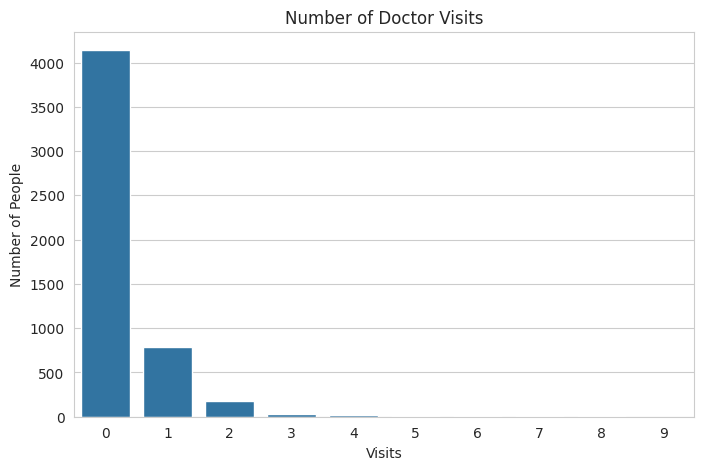

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(x='visits', data=df)
plt.title('Number of Doctor Visits')
plt.xlabel('Visits')
plt.ylabel('Number of People')
plt.show()

# Distributions of the other numeric columns

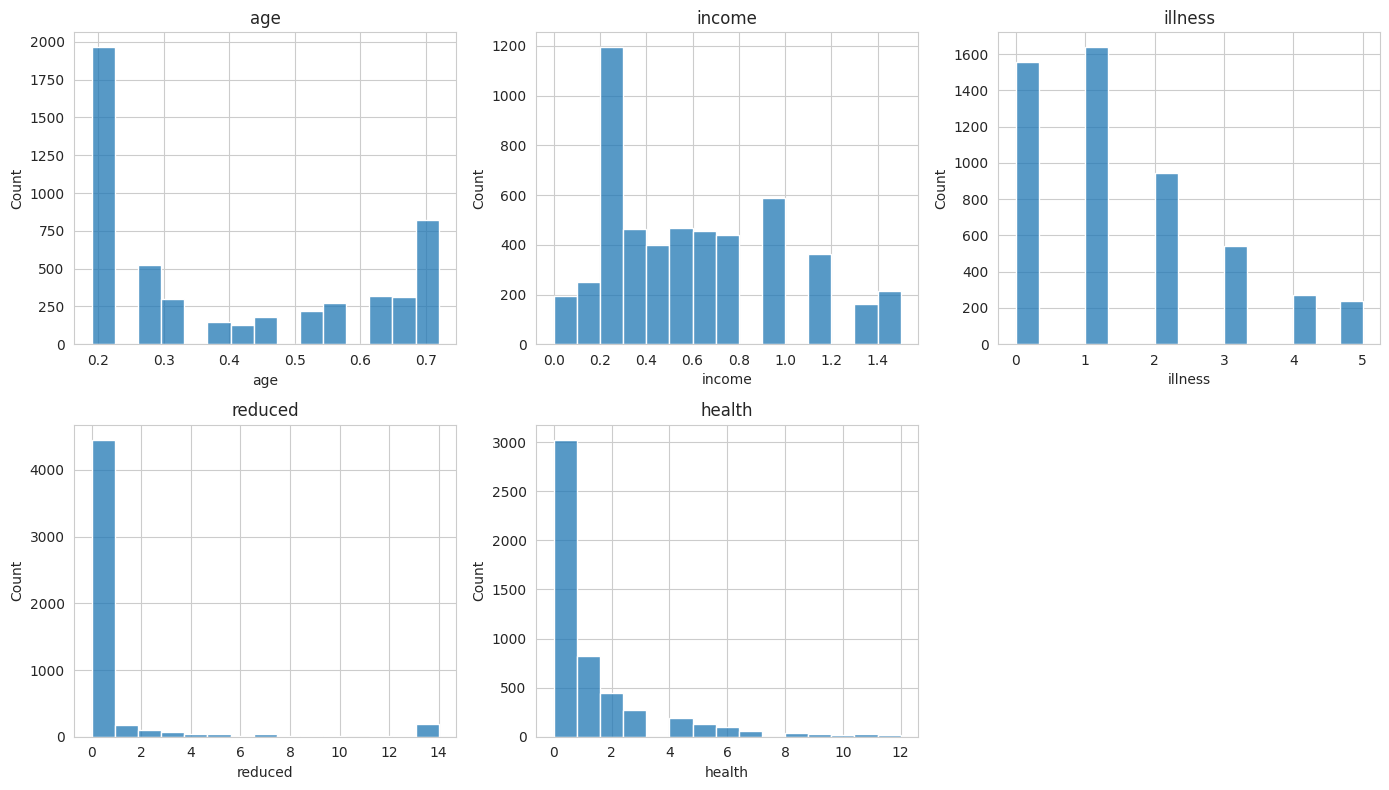

In [ ]:
# Plot all five other numeric columns in a grid

other_num_cols = ['age', 'income', 'illness', 'reduced', 'health']

plt.figure(figsize=(14, 8))

for i in range(len(other_num_cols)):
    plt.subplot(2, 3, i + 1)          # 2 rows, 3 columns of plots
    sns.histplot(df[other_num_cols[i]], bins=15)
    plt.title(other_num_cols[i])

plt.tight_layout()
plt.show()

# Spot the outliers

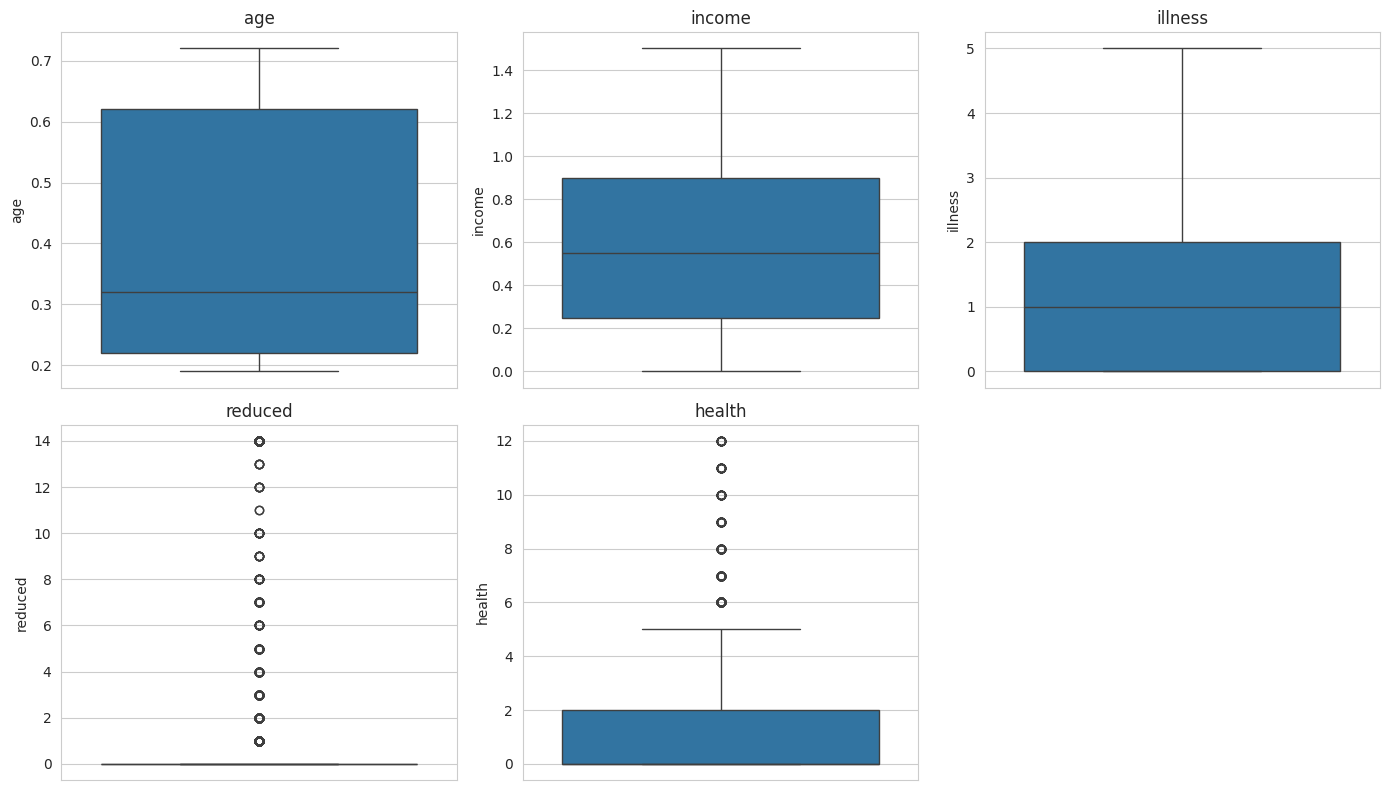

In [ ]:
plt.figure(figsize=(14, 8))

for i in range(len(other_num_cols)):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[other_num_cols[i]])
    plt.title(other_num_cols[i])

plt.tight_layout()
plt.show()

In [ ]:
for col in cat_cols:
    print(col)
    print(df[col].value_counts())
    print(round(df[col].value_counts(normalize=True) * 100, 1))
    print()

gender
gender
female    2702
male      2488
Name: count, dtype: int64
gender
female    52.1
male      47.9
Name: proportion, dtype: float64

private
private
no     2892
yes    2298
Name: count, dtype: int64
private
no     55.7
yes    44.3
Name: proportion, dtype: float64

freepoor
freepoor
no     4968
yes     222
Name: count, dtype: int64
freepoor
no     95.7
yes     4.3
Name: proportion, dtype: float64

freerepat
freerepat
no     4099
yes    1091
Name: count, dtype: int64
freerepat
no     79.0
yes    21.0
Name: proportion, dtype: float64

nchronic
nchronic
no     3098
yes    2092
Name: count, dtype: int64
nchronic
no     59.7
yes    40.3
Name: proportion, dtype: float64

lchronic
lchronic
no     4585
yes     605
Name: count, dtype: int64
lchronic
no     88.3
yes    11.7
Name: proportion, dtype: float64



## Column ->	Balance


---


gender ->	Fairly balanced, with slightly more females (about 52%)


---


private ->	Fairly balanced (about 44% yes)


---


nchronic ->	Moderately balanced (about 40% yes)


---


freerepat ->	Imbalanced (about 20% yes)


---


lchronic ->	Imbalanced (about 11% yes)


---


freepoor ->	Very imbalanced (about 4% yes, or roughly 200 people)

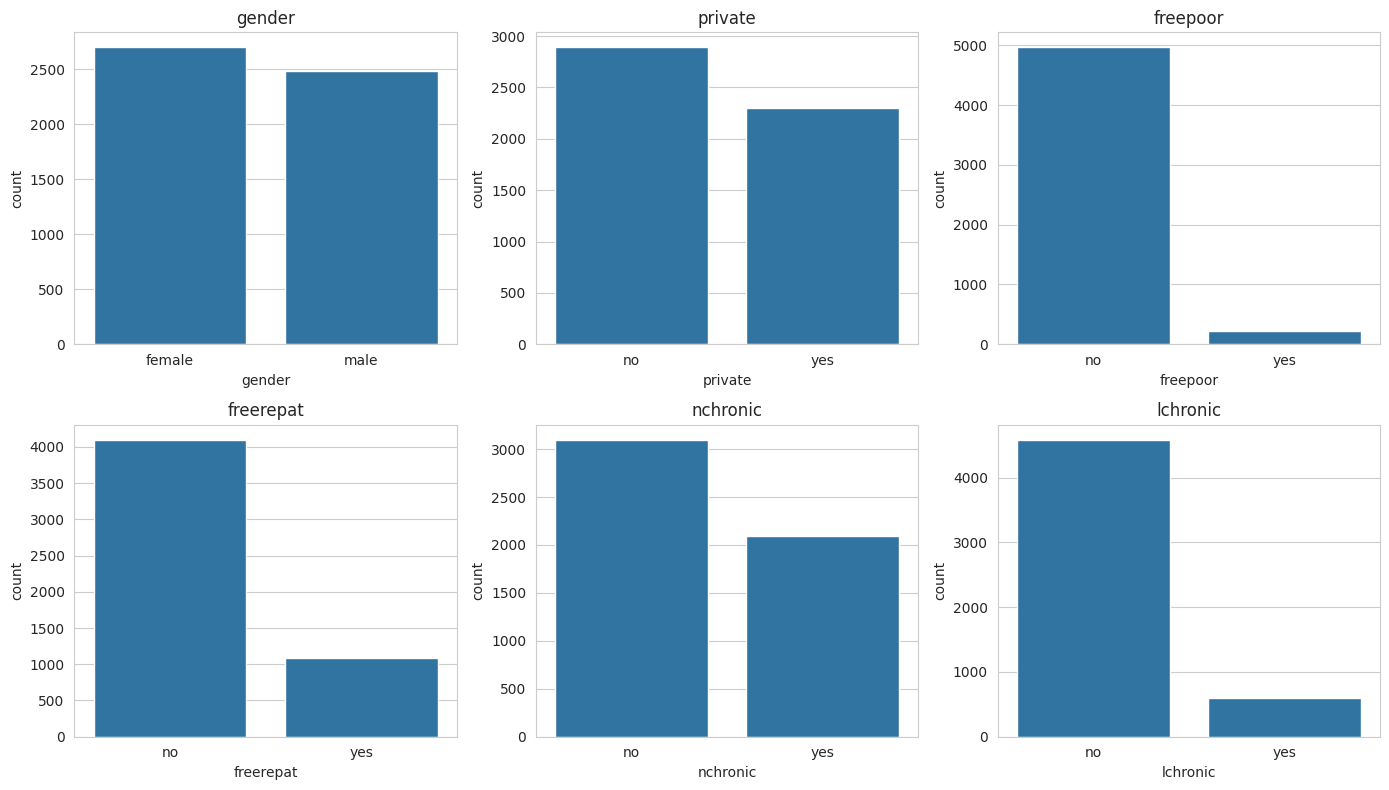

In [ ]:
plt.figure(figsize=(14, 8))

for i in range(len(cat_cols)):
    plt.subplot(2, 3, i + 1)
    sns.countplot(x=cat_cols[i], data=df)
    plt.title(cat_cols[i])

plt.tight_layout()
plt.show()

# Phase 3:

In [ ]:
# True if the person visited a doctor at least once, otherwise False
df['any_visit'] = df['visits'] > 0

# Overall share of people who visited
print("Overall % with at least one visit:", round(df['any_visit'].mean() * 100, 1))

Overall % with at least one visit: 20.2


In [ ]:
def compare_visits(col):
    # Group the people by the column, then calculate:
    # count of people, average visits, and % with at least one visit
    table = df.groupby(col, observed=True)['visits'].agg(['count', 'mean'])
    table['percent_with_visit'] = df.groupby(col, observed=True)['any_visit'].mean() * 100

    print(table.round(2))

    # Bar chart of average visits for each group
    table['mean'].plot(kind='bar', figsize=(6, 4))
    plt.title("Average visits by " + col)
    plt.ylabel("Average visits")
    plt.xticks(rotation=0)
    plt.show()

           count  mean  percent_with_visit
age_group                                 
19-30       2488  0.22               15.07
31-45        573  0.26               17.10
46-60        676  0.37               23.08
61-72       1453  0.43               28.91


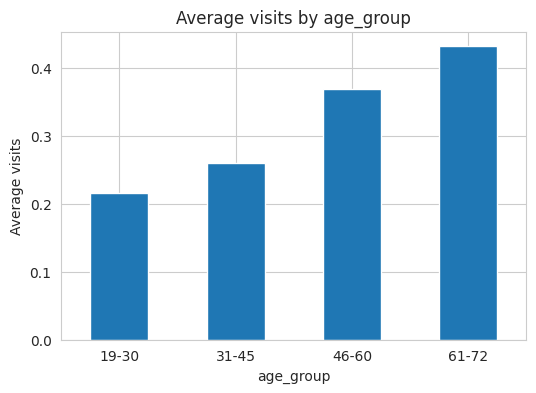

In [ ]:
# Age vs Visits

# Split age into groups. This assumes age is scaled (0.19 means 19 years).
# Confirm the units in your dataset guide.

age_bins = [0.18, 0.30, 0.45, 0.60, 0.73]
age_labels = ['19-30', '31-45', '46-60', '61-72']
df['age_group'] = pd.cut(df['age'], bins=age_bins, labels=age_labels)

compare_visits('age_group')

# Income vs Visits:

              count  mean  percent_with_visit
income_group                                 
Low            1638  0.40               25.64
Lower-middle   1329  0.31               20.09
Upper-middle   1485  0.23               16.57
High            738  0.22               15.72


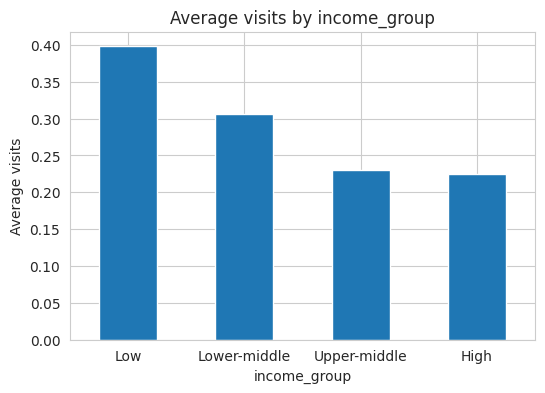

In [ ]:
# Split income into 4 groups
income_bins = [-0.01, 0.25, 0.55, 0.90, 1.5]
income_labels = ['Low', 'Lower-middle', 'Upper-middle', 'High']
df['income_group'] = pd.cut(df['income'], bins=income_bins, labels=income_labels)

compare_visits('income_group')

# Health condition vs visits:

              count  mean  percent_with_visit
health_group                                 
0 (best)       3026  0.20               15.04
1-2            1269  0.35               23.80
3+              895  0.58               32.63


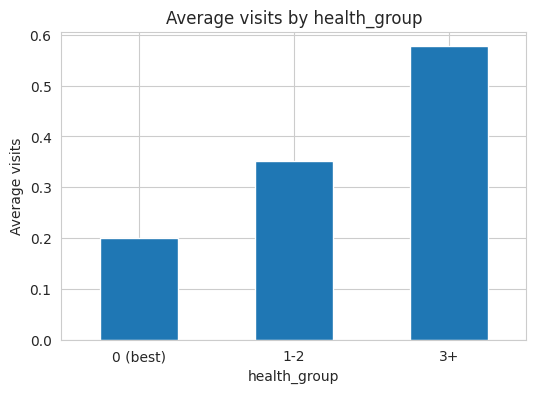

In [ ]:
# Most people score 0, so use small groups
health_bins = [-1, 0, 2, 12]
health_labels = ['0 (best)', '1-2', '3+']
df['health_group'] = pd.cut(df['health'], bins=health_bins, labels=health_labels)

compare_visits('health_group')

               count  mean  percent_with_visit
reduced_group                                 
0 days          4454  0.18               15.18
1+ days          736  1.01               50.68


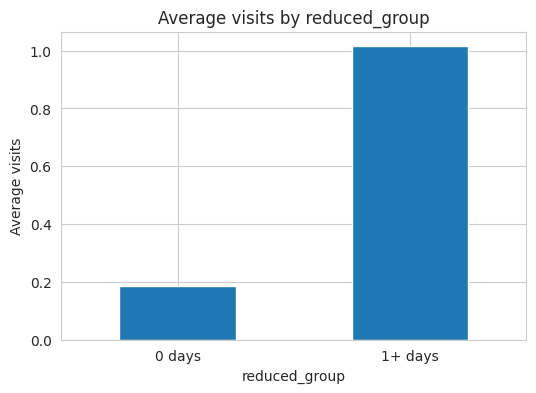

In [ ]:
# 0 days of reduced activity vs 1 or more days
df['reduced_group'] = df['reduced'].apply(lambda x: '0 days' if x == 0 else '1+ days')

compare_visits('reduced_group')

# Illness vs visits:

         count  mean  percent_with_visit
illness                                 
0         1554  0.08                6.76
1         1638  0.30               19.60
2          946  0.40               27.27
3          542  0.42               30.63
4          274  0.58               36.50
5          236  0.81               41.95


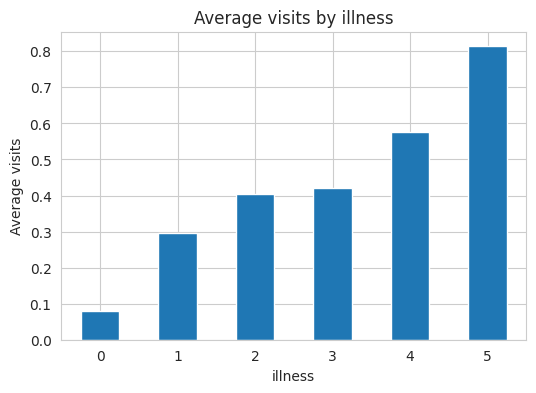

In [ ]:
# illness only has 6 values (0 to 5), so no grouping is needed
compare_visits('illness')

# Healthcare support vs visits:

          count  mean  percent_with_visit
nchronic                                 
no         3098  0.27               17.88
yes        2092  0.35               23.66


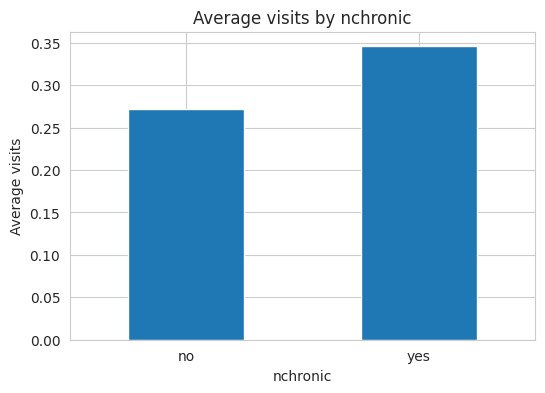

          count  mean  percent_with_visit
lchronic                                 
no         4585  0.26               18.26
yes         605  0.60               35.04


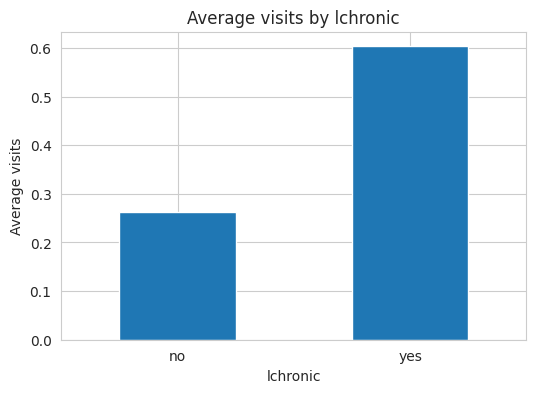

         count  mean  percent_with_visit
private                                 
no        2892  0.31               20.37
yes       2298  0.29               20.02


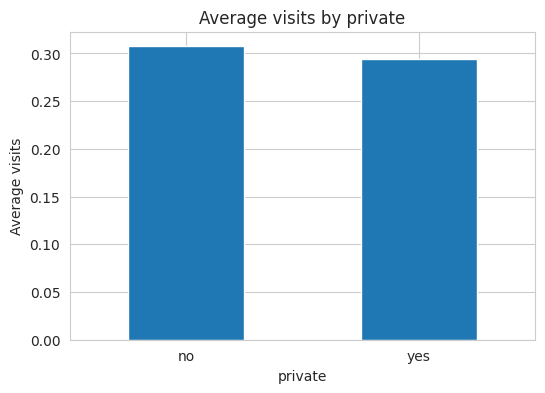

          count  mean  percent_with_visit
freepoor                                 
no         4968  0.31               20.71
yes         222  0.16                9.01


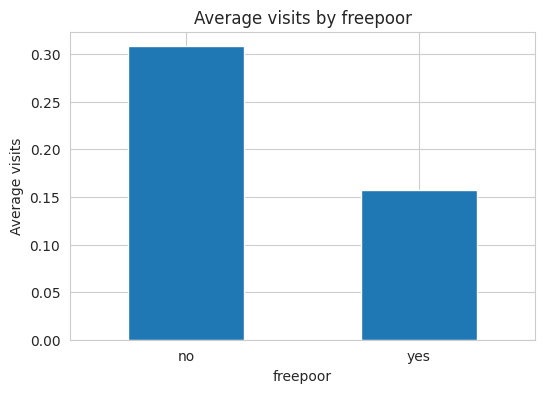

           count  mean  percent_with_visit
freerepat                                 
no          4099  0.26               17.17
yes         1091  0.47               31.62


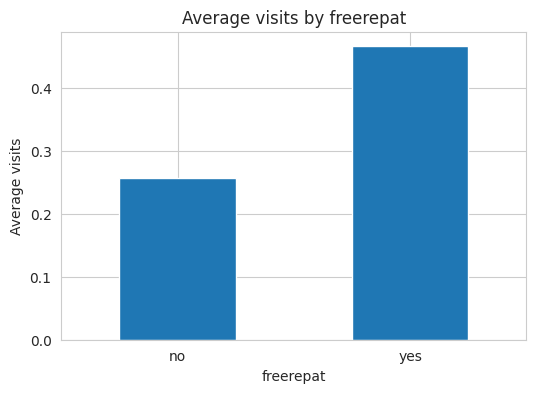

In [ ]:
compare_visits('nchronic')
compare_visits('lchronic')
compare_visits('private')
compare_visits('freepoor')
compare_visits('freerepat')

# Gender vs visits:

        count  mean  percent_with_visit
gender                                 
female   2702  0.36               24.43
male     2488  0.24               15.64


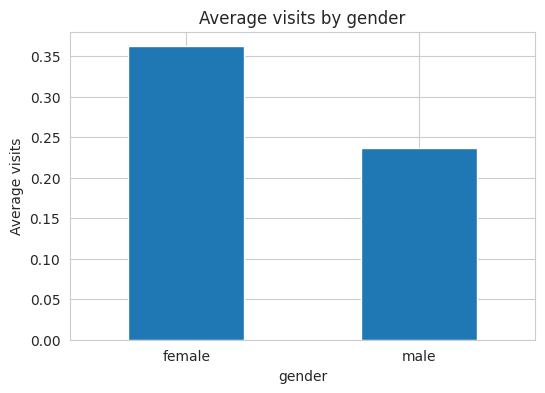

In [ ]:
compare_visits('gender')

# Findings so far based on the above analytics:
*   reduced is the strongest signal. The 736 people with one or more days of
reduced activity average about 5.6 times as many visits as the other 4,454, and half of them visited at least once.

*   illness shows a clear dose-response pattern. Average visits climb from 0.08 at 0 illnesses to 0.81 at 5, and the visited percentage rises from 6.8% to 42%. The only flat spot is between 2 and 3 illnesses (0.40 vs 0.42).

*   health follows the same direction. Higher scores go with more visits, and the “3+” group averages almost 3 times as many visits as the “0” group.

*   Age and visits rise together. The oldest group visits about twice as much as the youngest.

*   Lower income goes with more visits. The Low group averages nearly twice the visits of the High group. The gap between Upper-middle and High is small (0.23 vs 0.22), so most of the difference is between the low and middle groups.

*   Females visit more than males. The difference is about 0.12 visits on average, or about 9 percentage points in the share who visited.



          count  mean  percent_with_visit
nchronic                                 
no         3098  0.27               17.88
yes        2092  0.35               23.66


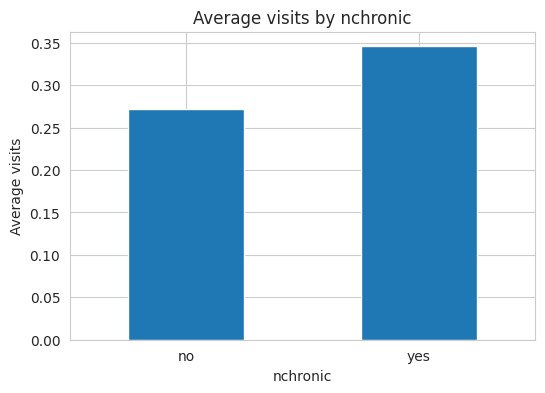

          count  mean  percent_with_visit
lchronic                                 
no         4585  0.26               18.26
yes         605  0.60               35.04


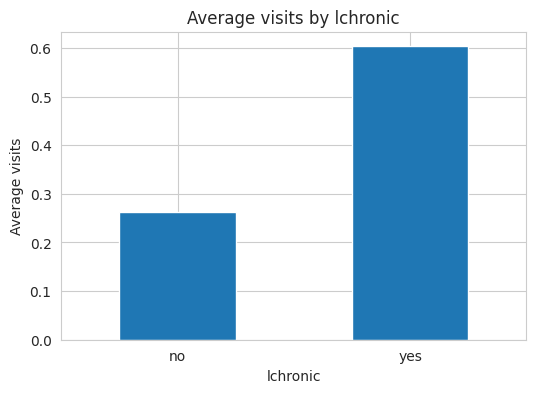

In [ ]:
compare_visits('nchronic')
compare_visits('lchronic')

# Main conclusions:
1.   Current health problems matter most. Reduced activity days, number of illnesses and the health score show the largest gaps. People who are currently unwell are the ones visiting doctors.
2.   A limiting chronic condition (lchronic) is a strong marker, and a non-limiting one (nchronic) is a weaker one.
3.   Demographics matter, but less. Older people, women and lower-income people visit somewhat more.
4.   Private insurance shows no association with visits in this dataset.
5.   The free-coverage columns point in opposite directions. freerepat = yes goes with more visits and freepoor = yes with fewer.

# NOTE:


*   All of these are associations, not causes.
*   freepoor rests on only 222 people.
*   The age and income groups are uneven in size, and the cut points were chosen by hand, so the exact numbers would shift slightly with different groups.
*   The top-ranked factors partly measure the same thing (how sick someone is), so their effects are not independent of each other.

# Phase 4:

# Correlation analysis:

In [ ]:
# Making a numeric-only copy for correlations

# Correlation needs numbers, so we turn the yes/no columns into 1/0
# We make a COPY so the original df is not changed
corr_df = df[['visits', 'age', 'income', 'illness', 'reduced', 'health']].copy()

yes_no_cols = ['private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']
for col in yes_no_cols:
    corr_df[col] = (df[col] == 'yes').astype(int)   # yes = 1, no = 0

corr_df['gender_female'] = (df['gender'] == 'female').astype(int)   # female = 1, male = 0

print(corr_df.shape)
corr_df

(5190, 12)


,visits,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic,gender_female
0,1,0.19,0.55,1,4,1,1,0,0,0,0,1
1,1,0.19,0.45,1,2,1,1,0,0,0,0,1
2,1,0.19,0.90,3,0,0,0,0,0,0,0,0
3,1,0.19,0.15,1,0,0,0,0,0,0,0,0
4,1,0.19,0.45,2,5,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
5185,0,0.22,0.55,0,0,0,0,0,0,0,0,1
5186,0,0.27,1.30,0,0,1,0,0,0,0,0,0
5187,0,0.37,0.25,1,0,1,0,0,1,0,0,1
5188,0,0.52,0.65,0,0,0,0,0,0,0,0,1


# Correlation heatmap:

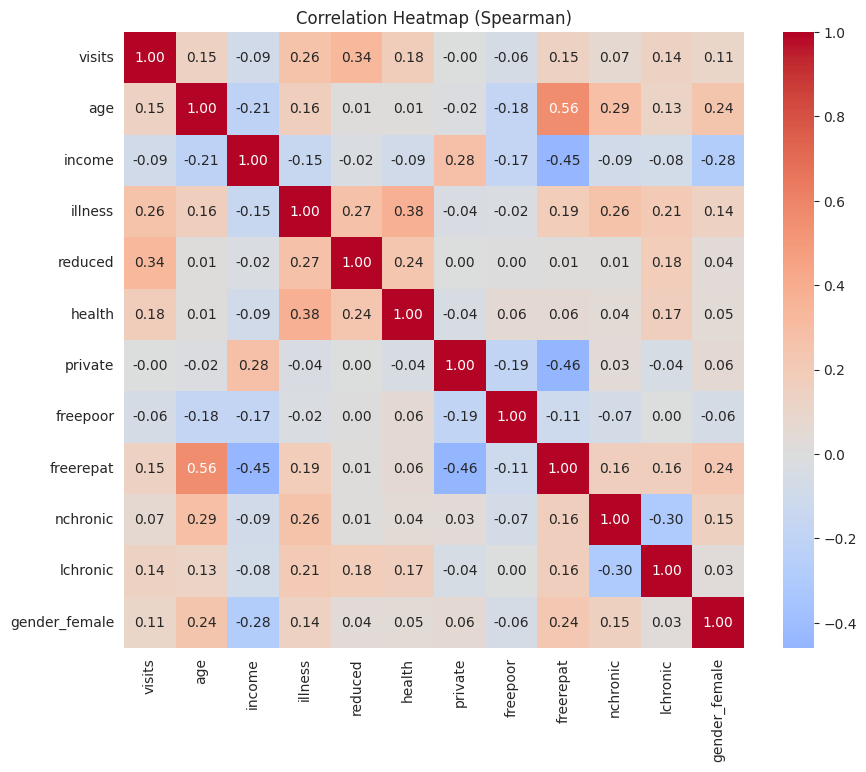

In [ ]:
# 'spearman' works better than the default when data is skewed or mostly zeros
corr_matrix = corr_df.corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap (Spearman)')
plt.show()

# Correlations findings(Spearman):


*   The ranking against visits matches Phase 3: reduced (0.34), illness (0.26), health (0.18), age (0.15), freerepat (0.15), lchronic (0.14), gender_female (0.11).
*   private (0.00), freepoor (-0.06) and income (-0.09) are close to zero.
*   All values are modest because visits is mostly zeros. Use the ranking, not the size of the numbers.


# Correlation of each factor with visits:

In [ ]:
# Sort the factors by how strongly they relate to visits
visits_corr = corr_matrix['visits'].drop('visits').sort_values(ascending=False)
print(visits_corr.round(2))

reduced          0.34
illness          0.26
health           0.18
age              0.15
freerepat        0.15
lchronic         0.14
gender_female    0.11
nchronic         0.07
private         -0.00
freepoor        -0.06
income          -0.09
Name: visits, dtype: float64


# Combined comparisons:

A helper that compares two factors at once:

In [ ]:
def compare_two(row_col, col_col):
    # Average visits for every combination of the two columns
    means = df.pivot_table(values='visits', index=row_col, columns=col_col,
                           aggfunc='mean', observed=True)
    # Number of people in every combination
    counts = df.pivot_table(values='visits', index=row_col, columns=col_col,
                            aggfunc='count', observed=True)

    print("Average visits:")
    print(means.round(2))
    print("\nNumber of people:")
    print(counts)

A simple illness grouping:

In [ ]:
# Group illness into 3 levels so each table cell has enough people
df['illness_group'] = pd.cut(df['illness'], bins=[-1, 0, 2, 5], labels=['0', '1-2', '3+'])

In [ ]:
compare_two('illness_group', 'gender')

Average visits:
gender         female  male
illness_group              
0                0.11  0.06
1-2              0.39  0.28
3+               0.58  0.51

Number of people:
gender         female  male
illness_group              
0                 679   875
1-2              1365  1219
3+                658   394


# Result (Gender vs illness):


*   Females are higher at every illness level (0.11 vs 0.06, 0.39 vs 0.28, 0.58 vs 0.51)

In [ ]:
compare_two('illness_group', 'age_group')

Average visits:
age_group      19-30  31-45  46-60  61-72
illness_group                            
0               0.05   0.05   0.07   0.16
1-2             0.29   0.30   0.41   0.41
3+              0.35   0.57   0.64   0.67

Number of people:
age_group      19-30  31-45  46-60  61-72
illness_group                            
0                835    188    196    335
1-2             1293    303    316    672
3+               360     82    164    446


# Result (Age vs illness):
*   Older groups are higher at every illness level, especially 46+

In [ ]:
compare_two('illness_group', 'income_group')

Average visits:
income_group    Low  Lower-middle  Upper-middle  High
illness_group                                        
0              0.14          0.06          0.06  0.06
1-2            0.38          0.35          0.27  0.32
3+             0.64          0.53          0.49  0.32

Number of people:
income_group   Low  Lower-middle  Upper-middle  High
illness_group                                       
0              384           386           514   270
1-2            793           663           755   373
3+             461           280           216    95


# Result (income vs illness):


*   Low income is higher in each illness group, with the widest gap at 3+ (0.64 vs 0.32)



In [ ]:
# Average profile of each group
profile_cols = ['age', 'income', 'illness', 'reduced', 'health']

print("By freerepat:")
print(df.groupby('freerepat', observed=True)[profile_cols].mean().round(2))

print("\nBy freepoor:")
print(df.groupby('freepoor', observed=True)[profile_cols].mean().round(2))

By freerepat:
            age  income  illness  reduced  health
freerepat                                        
no         0.34    0.66     1.29     0.74    1.14
yes        0.65    0.30     1.97     1.33    1.50

By freepoor:
           age  income  illness  reduced  health
freepoor                                        
no        0.41     0.6     1.44     0.87    1.19
yes       0.25     0.3     1.26     0.77    1.80


In [ ]:
compare_two('illness_group', 'freerepat')

Average visits:
freerepat        no   yes
illness_group            
0              0.06  0.19
1-2            0.31  0.43
3+             0.48  0.67

Number of people:
freerepat        no  yes
illness_group           
0              1346  208
1-2            2063  521
3+              690  362


# Result (freerepat vs illness):
*   Still higher within each illness level (0.19 vs 0.06, 0.43 vs 0.31, 0.67 vs 0.48)

In [ ]:
compare_two('income_group', 'freepoor')

Average visits:
freepoor        no   yes
income_group            
Low           0.42  0.19
Lower-middle  0.31  0.14
Upper-middle  0.23  0.00
High          0.23  0.00

Number of people:
freepoor        no  yes
income_group           
Low           1501  137
Lower-middle  1264   65
Upper-middle  1467   18
High           736    2


# Result (freepoor vs income):
The “yes” group is lower at each income level with enough people (0.19 vs 0.42, 0.14 vs 0.31)

In [ ]:
compare_two('lchronic', 'private')

Average visits:
private     no   yes
lchronic            
no        0.27  0.25
yes       0.57  0.65

Number of people:
private     no   yes
lchronic            
no        2518  2067
yes        374   231


# Result (lchronic vs private):
The lchronic gap is similar for both insurance types (about 0.57 to 0.65 vs 0.25 to 0.27)

# Check overlap between illness, reduced and health:
How closely do these three move together?

In [ ]:
overlap_cols = ['illness', 'reduced', 'health']
print(df[overlap_cols].corr(method='spearman').round(2))

         illness  reduced  health
illness     1.00     0.27    0.38
reduced     0.27     1.00    0.24
health      0.38     0.24    1.00


*   Their correlations are only 0.24 to 0.38, so they are related but not duplicates.
*   reduced is still much higher within every illness group (for example 0.95 vs 0.21 at 1-2 illnesses, and 1.13 vs 0.34 at 3+). It carries its own information beyond the illness count.



Average reduced and health at each illness level.

In [ ]:
print(df.groupby('illness')[['reduced', 'health']].mean().round(2))

         reduced  health
illness                 
0           0.05    0.43
1           0.94    0.98
2           1.04    1.59
3           1.35    1.84
4           1.84    2.81
5           2.73    3.27


Does reduced still matter at the same illness level?

In [ ]:
compare_two('illness_group', 'reduced_group')

Average visits:
reduced_group  0 days  1+ days
illness_group                 
0                0.07     0.64
1-2              0.21     0.95
3+               0.34     1.13

Number of people:
reduced_group  0 days  1+ days
illness_group                 
0                1543       11
1-2              2138      446
3+                773      279


# Phase 5:

# Key findings:
Dataset: 5,190 people and 13 columns, with no missing values. Doctor visits are rare: about 80% of people had zero visits, and only 20.2% visited at least once (average 0.30 visits).

# Why do some people visit a doctor more often than others?

In this dataset, the people who visit most are those who are currently unwell: they report days of reduced activity, more illnesses, poorer health scores, or a chronic condition that limits their activity. Beyond health, older people, women and lower-income people visit somewhat more, even when compared with others at the same illness level. Private insurance has no visible association with visits. The free-coverage columns show mixed results. People in the freerepat group visit more, partly because that group is older, poorer and sicker, while people in the freepoor group visit less.

# Limitations:


1.   Associations, not causes. These results show which factors go together with visits, not what causes them.
2.   With about 80% of people at zero visits, simple averages and correlations look weak. This is why the analysis used group averages and the “visited at least once” percentage.
1.   Small groups. freepoor has only 222 people, and some combination tables had cells with fewer than 30 people (including 2 and 11 people in two cells). Those values were not interpreted.
2.   Hand-chosen groups. The age and income cut points were my choice, and different cut points would shift the exact numbers slightly.
1.   Only one factor controlled at a time. The combined tables adjust for one other variable at once, so overlaps such as age with freerepat were only partly separated.
2.   Unconfirmed definitions. The meaning of freepoor, freerepat, nchronic and lchronic should be confirmed against the dataset guide. Also confirm the units of the scaled age and income columns and what period reduced covers.
1.   Duplicates kept. The 1,320 duplicate rows were kept because they likely represent different people with identical profiles (removing them would raise average visits from 0.30 to 0.39).

# Conclusion:

This analysis explored what is associated with the number of doctor visits among 5,190 people. Doctor visits were rare, with about 80% of people having none. Health status was the strongest correlate: people with reduced-activity days, more illnesses, worse health scores or an activity-limiting chronic condition were far more likely to visit a doctor, and these patterns held when compared at similar illness levels. Older age, female gender and lower income were also linked to more visits, with smaller effects. Private insurance showed no association, while the two free-coverage groups showed opposite patterns that are partly explained by differences in age, income and health. These findings describe associations only. A count regression model is the recommended next step to separate the independent effect of each factor.